In [1]:
import os

folders = [
    "env",
    "controllers",
    "experiments",
    "plots"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

In [2]:
!ls

Swarm.ipynb  controllers  env  experiments  plots


In [3]:
%%writefile env/point_mass_3d.py
import numpy as np


class PointMass3DEnv:
    def __init__(self, num_agents, dt=0.1):
        """
        num_agents: how many robots
        dt: time step (seconds)
        """
        self.num_agents = num_agents
        self.dt = dt

        # Positions of all agents (N x 3)
        self.positions = np.random.uniform(
            low=-1.0,
            high=1.0,
            size=(num_agents, 3)
        )

    def step(self, velocities):
        """
        velocities: desired velocity for each agent (N x 3)
        """
        self.positions = self.positions + velocities * self.dt
        return self.positions

Writing env/point_mass_3d.py


In [4]:
%%writefile controllers/baseline.py
import numpy as np


class BaselineFormationController:
    def __init__(self, desired_spacing=1.0, gain=1.0):
        """
        desired_spacing: distance between neighboring agents
        gain: how aggressively agents move
        """
        self.desired_spacing = desired_spacing
        self.gain = gain

    def compute_velocities(self, positions):
        """
        positions: current positions of agents (N x 3)
        returns: velocities for agents (N x 3)
        """
        num_agents = positions.shape[0]
        velocities = np.zeros_like(positions)

        for i in range(num_agents):
            force = np.zeros(3)

            # Interact with left neighbor
            if i > 0:
                diff = positions[i] - positions[i - 1]
                desired = np.array([self.desired_spacing, 0.0, 0.0])
                force += (desired - diff)

            # Interact with right neighbor
            if i < num_agents - 1:
                diff = positions[i] - positions[i + 1]
                desired = np.array([-self.desired_spacing, 0.0, 0.0])
                force += (desired - diff)

            velocities[i] = self.gain * force

        return velocities

Writing controllers/baseline.py


In [5]:
import numpy as np

from env.point_mass_3d import PointMass3DEnv
from controllers.baseline import BaselineFormationController

In [6]:
# Number of agents
N = 5

# Create environment
env = PointMass3DEnv(num_agents=N, dt=0.1)

# Create controller
controller = BaselineFormationController(
    desired_spacing=1.0,
    gain=0.5
)

In [7]:
print("Initial positions:")
print(env.positions)

Initial positions:
[[-0.50064162  0.78274843 -0.1735087 ]
 [ 0.73641172  0.89899366 -0.1393902 ]
 [-0.16461706 -0.01587375  0.44526439]
 [-0.67684355 -0.39422083 -0.5151038 ]
 [-0.80086954  0.92166971  0.30367554]]


In [8]:
num_steps = 100

for step in range(num_steps):
    velocities = controller.compute_velocities(env.positions)
    env.step(velocities)

In [9]:
print("Final positions:")
print(env.positions)

Final positions:
[[-1.94436039  0.47371082 -0.02873433]
 [-1.07283618  0.46001301 -0.02376376]
 [-0.28103022  0.43827846 -0.01576976]
 [ 0.51038631  0.41707594 -0.00783491]
 [ 1.38128042  0.40423899 -0.00296003]]


In [10]:
def formation_error(positions, desired_spacing):
    """
    positions: (N x 3) array
    desired_spacing: float
    returns: scalar error
    """
    num_agents = positions.shape[0]
    errors = []

    for i in range(num_agents - 1):
        diff = positions[i + 1] - positions[i]
        distance = np.linalg.norm(diff)
        errors.append(abs(distance - desired_spacing))

    return np.mean(errors)

In [11]:
# Reset environment
env = PointMass3DEnv(num_agents=N, dt=0.1)

errors_over_time = []

num_steps = 100

for step in range(num_steps):
    velocities = controller.compute_velocities(env.positions)
    env.step(velocities)

    err = formation_error(env.positions, desired_spacing=1.0)
    errors_over_time.append(err)

In [12]:
print("First 10 error values:")
print(errors_over_time[:10])

print("\nLast 10 error values:")
print(errors_over_time[-10:])

First 10 error values:
[np.float64(0.4895073531409283), np.float64(0.30113570126749445), np.float64(0.230092368785744), np.float64(0.20551414190556125), np.float64(0.2415170662412329), np.float64(0.3423754736786003), np.float64(0.42752306646024985), np.float64(0.4957736950089941), np.float64(0.5499960845027578), np.float64(0.5925049025156105)]

Last 10 error values:
[np.float64(0.18538673432159697), np.float64(0.18186464536078212), np.float64(0.17840894746972058), np.float64(0.17501841811440247), np.float64(0.1716918554710487), np.float64(0.16842807820409894), np.float64(0.16522592523546728), np.float64(0.1620842555063338), np.float64(0.1590019477326065), np.float64(0.1559779001550757)]


In [13]:
# Reset environment
env = PointMass3DEnv(num_agents=N, dt=0.1)

errors_over_time = []
communications_over_time = []

num_steps = 100

for step in range(num_steps):
    # Communication counting (baseline)
    communications_this_step = 2 * (N - 1)
    communications_over_time.append(communications_this_step)

    velocities = controller.compute_velocities(env.positions)
    env.step(velocities)

    err = formation_error(env.positions, desired_spacing=1.0)
    errors_over_time.append(err)

In [14]:
print("First 5 communication counts:")
print(communications_over_time[:5])

print("Total communications:")
print(sum(communications_over_time))

First 5 communication counts:
[8, 8, 8, 8, 8]
Total communications:
800


error plot

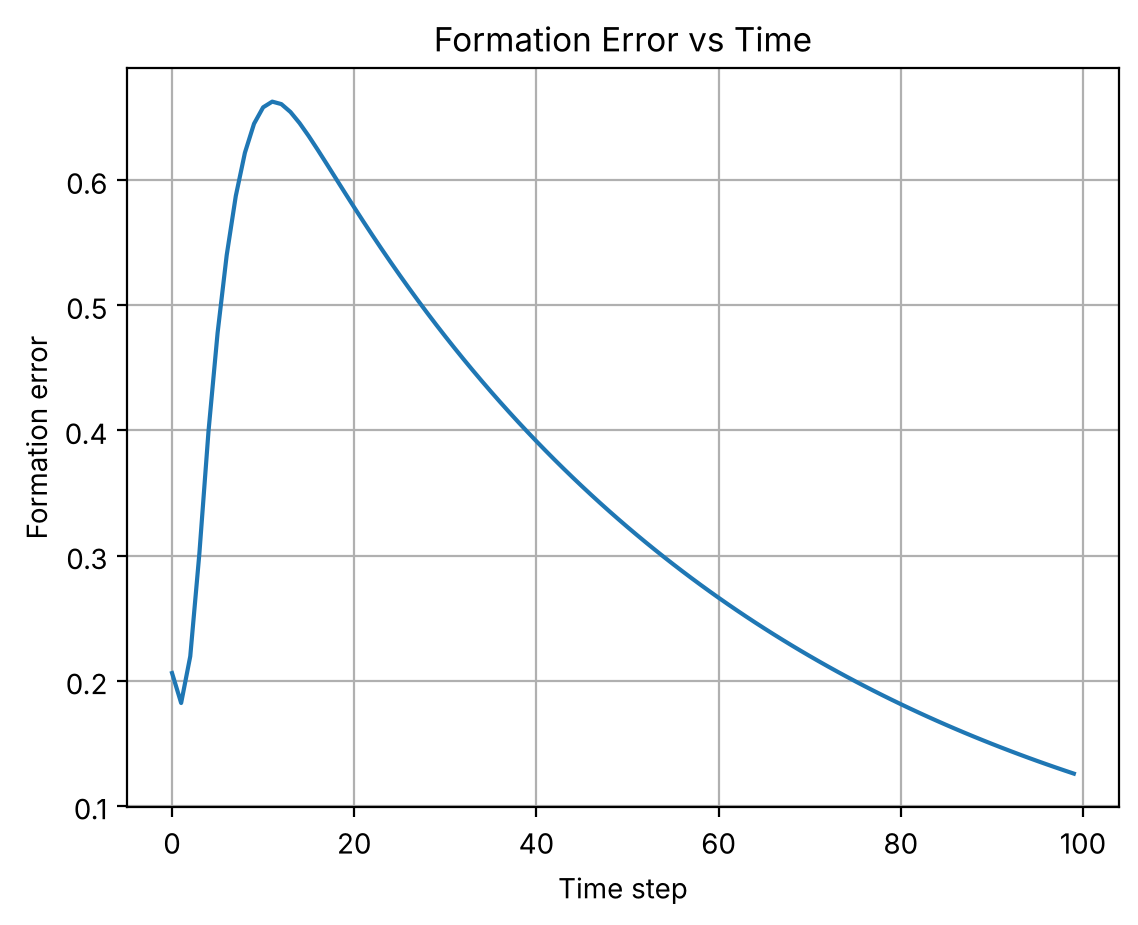

In [15]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(errors_over_time)
plt.xlabel("Time step")
plt.ylabel("Formation error")
plt.title("Formation Error vs Time")
plt.grid()
plt.show()

communication plot

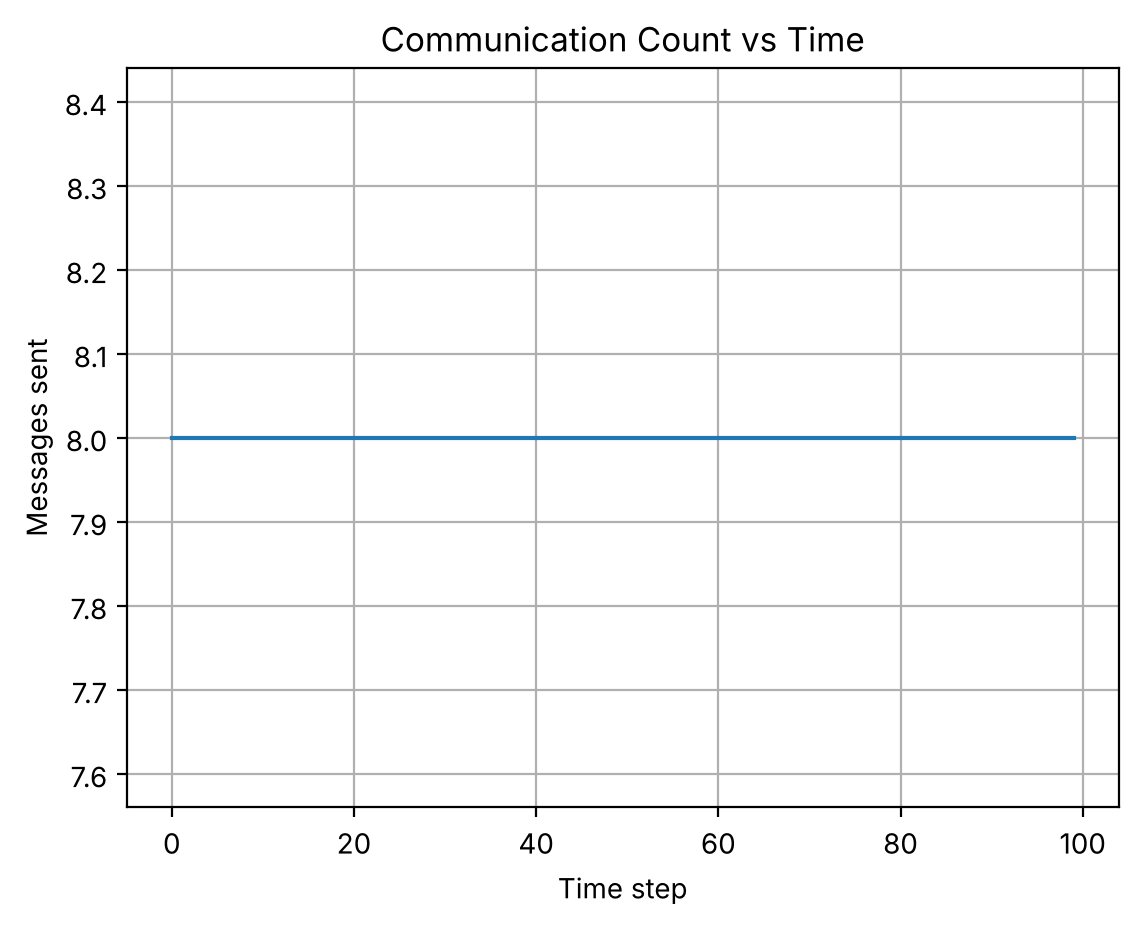

In [16]:
plt.figure()
plt.plot(communications_over_time)
plt.xlabel("Time step")
plt.ylabel("Messages sent")
plt.title("Communication Count vs Time")
plt.grid()
plt.show()

trajectory storage

In [17]:
# Reset environment
env = PointMass3DEnv(num_agents=N, dt=0.1)

errors_over_time = []
communications_over_time = []
trajectory = []  # <-- THIS IS NEW

num_steps = 100

for step in range(num_steps):
    # Store positions (IMPORTANT: copy!)
    trajectory.append(env.positions.copy())

    # Communication counting
    communications_over_time.append(2 * (N - 1))

    velocities = controller.compute_velocities(env.positions)
    env.step(velocities)

    err = formation_error(env.positions, desired_spacing=1.0)
    errors_over_time.append(err)

In [18]:
print(len(trajectory))          # number of time steps
print(trajectory[0].shape)      # (N, 3)
print(trajectory[-1].shape)     # (N, 3)

100
(5, 3)
(5, 3)


3D plotting

In [19]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation

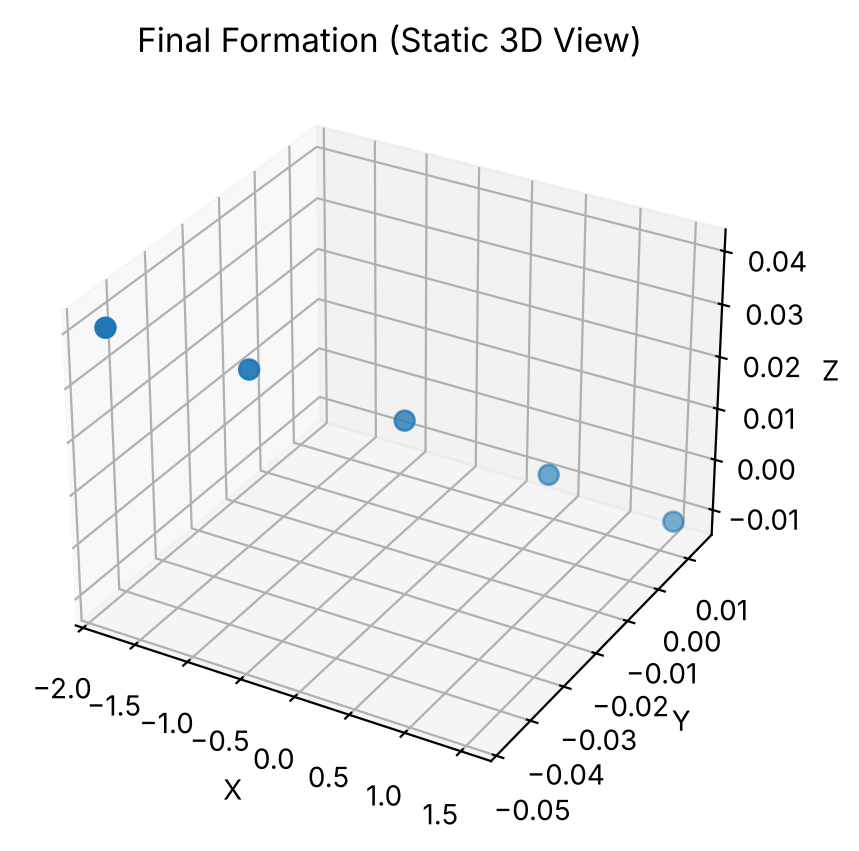

In [20]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

positions = trajectory[-1]  # final positions

ax.scatter(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    s=50
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_title("Final Formation (Static 3D View)")

plt.show()

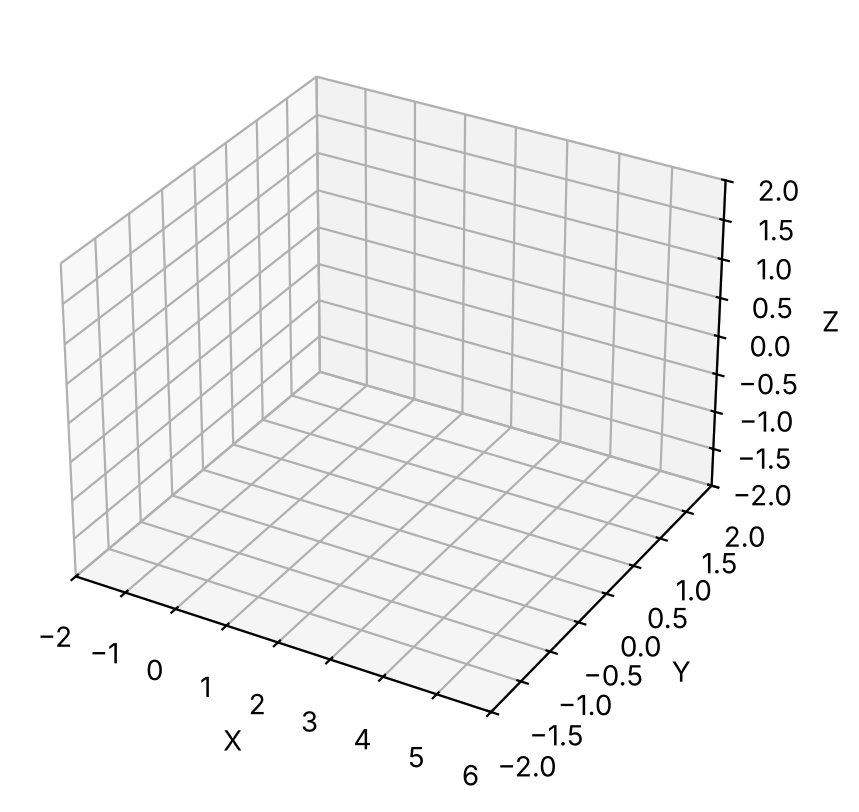

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Axis limits (IMPORTANT for stable animation)
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

scatter = ax.scatter([], [], [], s=50)

In [22]:
def init():
    scatter._offsets3d = ([], [], [])
    return scatter,

In [23]:
def update(frame):
    positions = trajectory[frame]

    scatter._offsets3d = (
        positions[:, 0],
        positions[:, 1],
        positions[:, 2]
    )

    ax.set_title(f"Swarm Formation — Step {frame}")
    return scatter,

In [24]:
ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(trajectory),
    init_func=init,
    interval=100,
    blit=False
)

plt.show()

In [ ]:
from IPython.display import HTML
HTML(ani.to_jshtml())

In [26]:
from matplotlib.animation import PillowWriter

In [27]:
gif_path = "plots/swarm_formation.gif"

ani.save(
    gif_path,
    writer=PillowWriter(fps=10)
)

print(f"Saved animation to {gif_path}")

Saved animation to plots/swarm_formation.gif


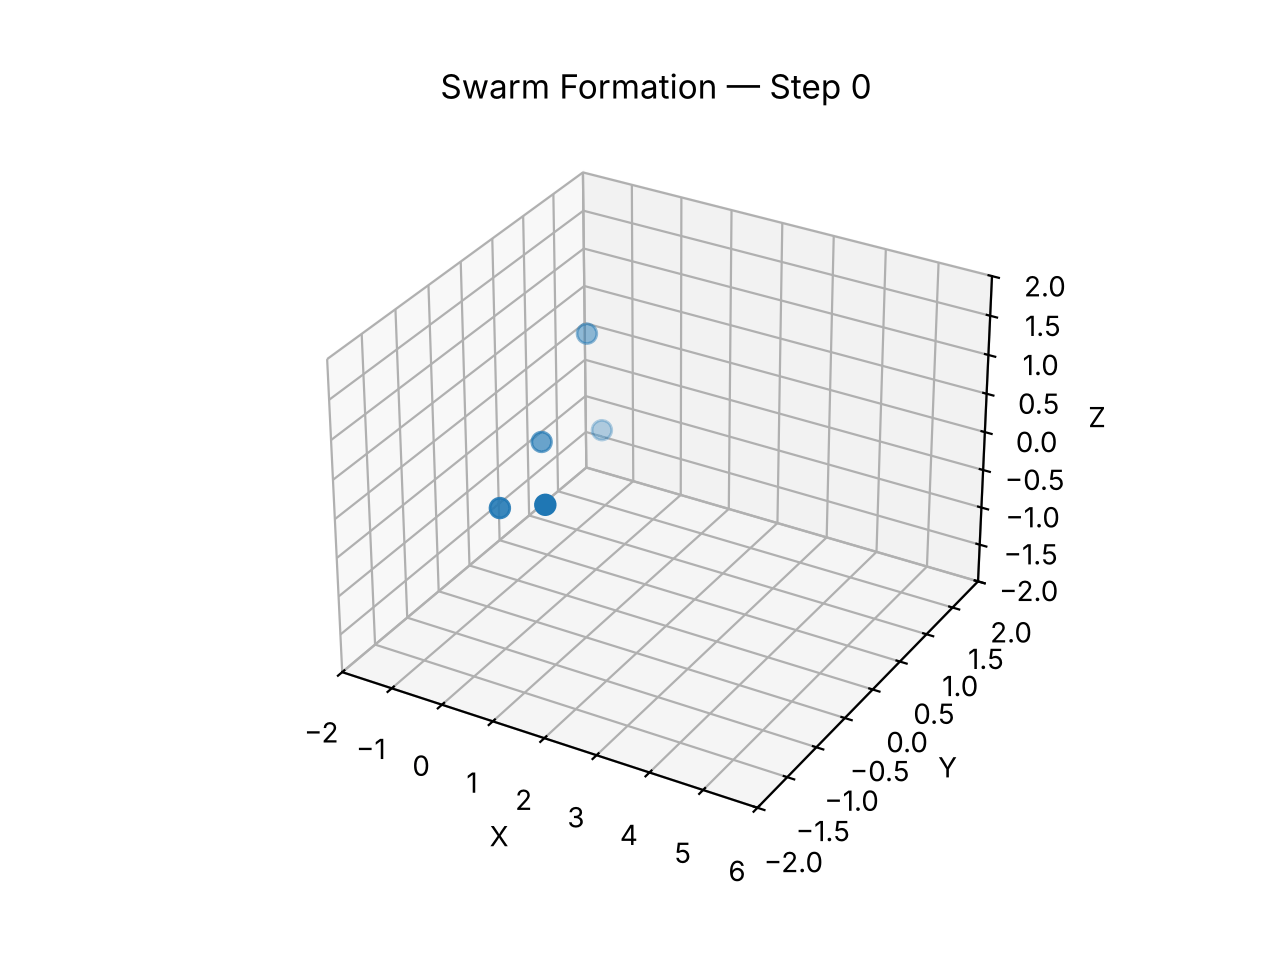

In [28]:
from IPython.display import Image, display

display(Image(filename="plots/swarm_formation.gif"))

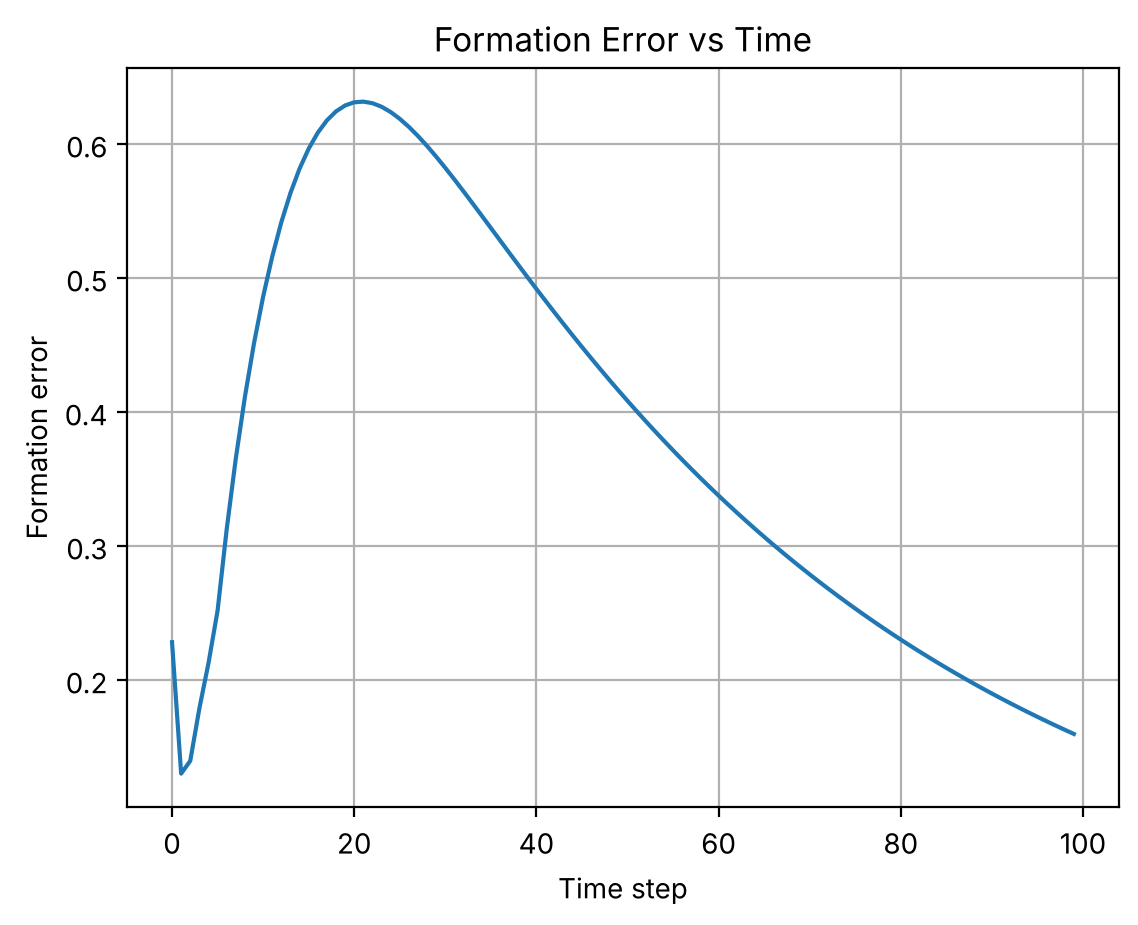

In [29]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(errors_over_time)
plt.xlabel("Time step")
plt.ylabel("Formation error")
plt.title("Formation Error vs Time")
plt.grid()

plt.savefig("plots/formation_error.png", dpi=300, bbox_inches="tight")
plt.show()

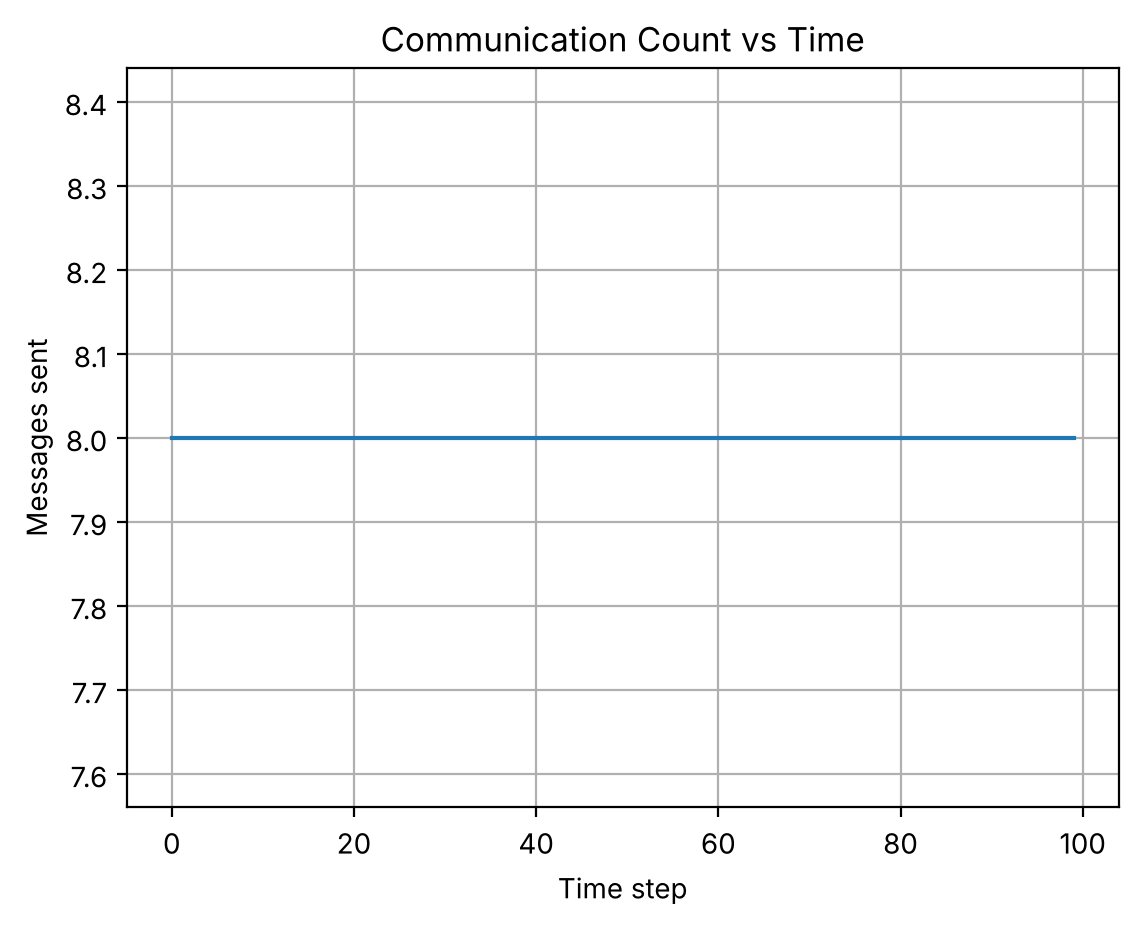

In [30]:
plt.figure()
plt.plot(communications_over_time)
plt.xlabel("Time step")
plt.ylabel("Messages sent")
plt.title("Communication Count vs Time")
plt.grid()

plt.savefig("plots/communication_count.png", dpi=300, bbox_inches="tight")
plt.show()

# Part 2 — Communication-efficient swarm formations

The baseline controller above works, but every robot talks to its neighbours **every single step** (`2 * (N - 1)` messages per step, forever — even after the line has formed).

This part of the project:

1. **Generalises the controller** to any formation shape (line, V, circle, 3D grid) and any communication graph (chain, ring, complete).
2. Adds an **event-triggered controller**: a robot only broadcasts its position when it has drifted more than a threshold from the last position it sent. Once the swarm settles, communication drops to ~zero.
3. **Compares** periodic vs event-triggered on formation error *and* number of messages.
4. Adds a **test suite** (`tests/test_swarm.py`, run with pytest) that checks convergence over many random seeds, swarm sizes and shapes — the "testing needed" from the last commit.

**Control law** (displacement-based consensus). Agent *i* with neighbours *N(i)* and desired offset *o_i*:

$$u_i = k \sum_{j \in N(i)} \big[(\hat p_j - \hat p_i) - (o_j - o_i)\big]$$

For the periodic controller $\hat p = p$ (true positions, sent every step). For the event-triggered one, $\hat p_i$ is the last position agent *i* broadcast, refreshed only when $\lVert p_i - \hat p_i \rVert > c_0 + c_1 e^{-\alpha t}$.

With the line offsets and a chain graph, this law is **exactly** the baseline controller (a test below checks that).

In [31]:
for folder in ["env", "controllers", "experiments", "plots", "tests"]:
    os.makedirs(folder, exist_ok=True)
open("env/__init__.py", "a").close()
open("controllers/__init__.py", "a").close()
open("experiments/__init__.py", "a").close()

## Formation shapes

In [32]:
%%writefile controllers/formations.py
import numpy as np


def line(n, spacing=1.0):
    """Agents on the x-axis, `spacing` apart, centred on the origin."""
    offsets = np.zeros((n, 3))
    offsets[:, 0] = np.arange(n) * spacing
    return offsets - offsets.mean(axis=0)


def v_shape(n, spacing=1.0, angle_deg=30.0):
    """Leader at the apex, the others alternate left / right arms behind it."""
    a = np.deg2rad(angle_deg)
    offsets = np.zeros((n, 3))
    for k in range(1, n):
        arm = (k + 1) // 2
        side = 1 if k % 2 else -1
        offsets[k] = [-arm * spacing * np.cos(a), side * arm * spacing * np.sin(a), 0.0]
    return offsets - offsets.mean(axis=0)


def circle(n, spacing=1.0):
    """Ring in the x-y plane; neighbouring agents are `spacing` apart."""
    radius = spacing / (2 * np.sin(np.pi / n))
    theta = 2 * np.pi * np.arange(n) / n
    return np.stack([radius * np.cos(theta), radius * np.sin(theta), np.zeros(n)], axis=1)


def grid3d(n, spacing=1.0):
    """Fill a cube lattice (x first, then y, then z) with n agents."""
    side = int(np.ceil(n ** (1 / 3) - 1e-9))
    pts = [(x, y, z) for z in range(side) for y in range(side) for x in range(side)][:n]
    offsets = np.array(pts, dtype=float) * spacing
    return offsets - offsets.mean(axis=0)


SHAPES = {"line": line, "v": v_shape, "circle": circle, "grid3d": grid3d}


def make(shape, n, spacing=1.0):
    return SHAPES[shape](n, spacing)

Writing controllers/formations.py


## Communication graphs

In [33]:
%%writefile controllers/graphs.py
def edges(kind, n):
    """Undirected edges (i, j), i < j, of a communication graph."""
    if kind == "chain":
        return [(i, i + 1) for i in range(n - 1)]
    if kind == "ring":
        return [(i, i + 1) for i in range(n - 1)] + ([(0, n - 1)] if n > 2 else [])
    if kind == "complete":
        return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError(f"unknown graph kind: {kind}")


def neighbours(edge_list, n):
    nbrs = [[] for _ in range(n)]
    for i, j in edge_list:
        nbrs[i].append(j)
        nbrs[j].append(i)
    return nbrs

Writing controllers/graphs.py


## Controllers: periodic vs event-triggered

In [34]:
%%writefile controllers/consensus.py
import numpy as np

from controllers.graphs import edges, neighbours


class FormationController:
    """Periodic displacement-based formation control.

    Every agent sends its position to each neighbour every step, so
    messages per step = sum of degrees = 2 * |E|.
    """

    def __init__(self, offsets, graph="chain", gain=0.5):
        self.offsets = np.asarray(offsets, dtype=float)
        self.n = len(self.offsets)
        self.edges = edges(graph, self.n)
        self.nbrs = neighbours(self.edges, self.n)
        self.gain = gain
        self.last_messages = 0

    def reset(self):
        self.last_messages = 0

    def _law(self, p_hat):
        v = np.zeros_like(p_hat)
        for i in range(self.n):
            for j in self.nbrs[i]:
                v[i] += (p_hat[j] - p_hat[i]) - (self.offsets[j] - self.offsets[i])
        return self.gain * v

    def compute_velocities(self, positions):
        self.last_messages = 2 * len(self.edges)
        return self._law(positions)

Writing controllers/consensus.py


In [35]:
%%writefile controllers/event_triggered.py
import numpy as np

from controllers.consensus import FormationController


class EventTriggeredFormationController(FormationController):
    """Same control law, but agent i only re-broadcasts its position when it
    has moved more than threshold(t) = c0 + c1 * exp(-alpha * t) away from
    the last position it sent. Neighbours use the last *broadcast* values.
    """

    def __init__(self, offsets, graph="chain", gain=0.5, dt=0.1,
                 c0=0.01, c1=0.2, alpha=0.5):
        super().__init__(offsets, graph, gain)
        self.dt = dt
        self.c0, self.c1, self.alpha = c0, c1, alpha
        self.reset()

    def reset(self):
        self.t = 0.0
        self.p_hat = None
        self.last_messages = 0
        self.broadcasts = 0

    def threshold(self):
        return self.c0 + self.c1 * np.exp(-self.alpha * self.t)

    def compute_velocities(self, positions):
        positions = np.asarray(positions, dtype=float)
        messages = 0
        if self.p_hat is None:  # everybody announces themselves once
            self.p_hat = positions.copy()
            messages = sum(len(nb) for nb in self.nbrs)
            self.broadcasts += self.n
        else:
            drift = np.linalg.norm(positions - self.p_hat, axis=1)
            fire = drift > self.threshold()
            for i in np.flatnonzero(fire):
                self.p_hat[i] = positions[i]
                messages += len(self.nbrs[i])
            self.broadcasts += int(fire.sum())

        self.last_messages = messages
        self.t += self.dt
        return self._law(self.p_hat)

Writing controllers/event_triggered.py


## Metrics and experiment runner

In [36]:
%%writefile experiments/metrics.py
import numpy as np


def offset_error(positions, offsets):
    """Mean over all agent pairs of ||(p_j - p_i) - (o_j - o_i)||.
    Zero exactly when the swarm is a translated copy of the formation."""
    p, o = np.asarray(positions), np.asarray(offsets)
    n = len(p)
    iu, ju = np.triu_indices(n, k=1)
    return float(np.mean(np.linalg.norm((p[ju] - p[iu]) - (o[ju] - o[iu]), axis=1)))


def min_distance(positions):
    p = np.asarray(positions)
    d = np.linalg.norm(p[:, None, :] - p[None, :, :], axis=-1)
    d[np.diag_indices(len(p))] = np.inf
    return float(d.min())

Writing experiments/metrics.py


In [37]:
%%writefile experiments/runner.py
import numpy as np

from env.point_mass_3d import PointMass3DEnv
from experiments.metrics import offset_error, min_distance


def run(controller, offsets, steps=300, dt=0.1, seed=0):
    """Simulate one episode. Returns a dict of per-step histories."""
    np.random.seed(seed)  # PointMass3DEnv uses the global RNG
    env = PointMass3DEnv(num_agents=len(offsets), dt=dt)
    controller.reset()

    errors, messages, min_dists, trajectory = [], [], [], []
    for _ in range(steps):
        trajectory.append(env.positions.copy())
        v = controller.compute_velocities(env.positions)
        env.step(v)
        messages.append(controller.last_messages)
        errors.append(offset_error(env.positions, offsets))
        min_dists.append(min_distance(env.positions))

    return {
        "errors": np.array(errors),
        "messages": np.array(messages),
        "min_dist": np.array(min_dists),
        "trajectory": np.array(trajectory),
        "final_error": errors[-1],
        "total_messages": int(np.sum(messages)),
    }

Writing experiments/runner.py


In [38]:
import importlib, sys
for m in [m for m in sys.modules if m.split(".")[0] in ("controllers", "experiments", "env")]:
    del sys.modules[m]  # pick up freshly written files on re-runs

from controllers import formations
from controllers.consensus import FormationController
from controllers.event_triggered import EventTriggeredFormationController
from experiments.runner import run

DT = 0.1
STEPS = 500

## Periodic vs event-triggered — V formation, 7 robots

In [39]:
N2 = 7
offsets = formations.make("v", N2)

periodic = run(FormationController(offsets, graph="chain", gain=0.5), offsets, STEPS, DT, seed=1)
event = run(EventTriggeredFormationController(offsets, graph="chain", gain=0.5, dt=DT), offsets, STEPS, DT, seed=1)

print(f"{'':16}{'final error':>14}{'messages':>12}")
print(f"{'periodic':16}{periodic['final_error']:>14.4f}{periodic['total_messages']:>12}")
print(f"{'event-triggered':16}{event['final_error']:>14.4f}{event['total_messages']:>12}")
print(f"\nMessages saved: {100 * (1 - event['total_messages'] / periodic['total_messages']):.1f}%")

                   final error    messages
periodic                0.0089        6000
event-triggered         0.0085         647

Messages saved: 89.2%


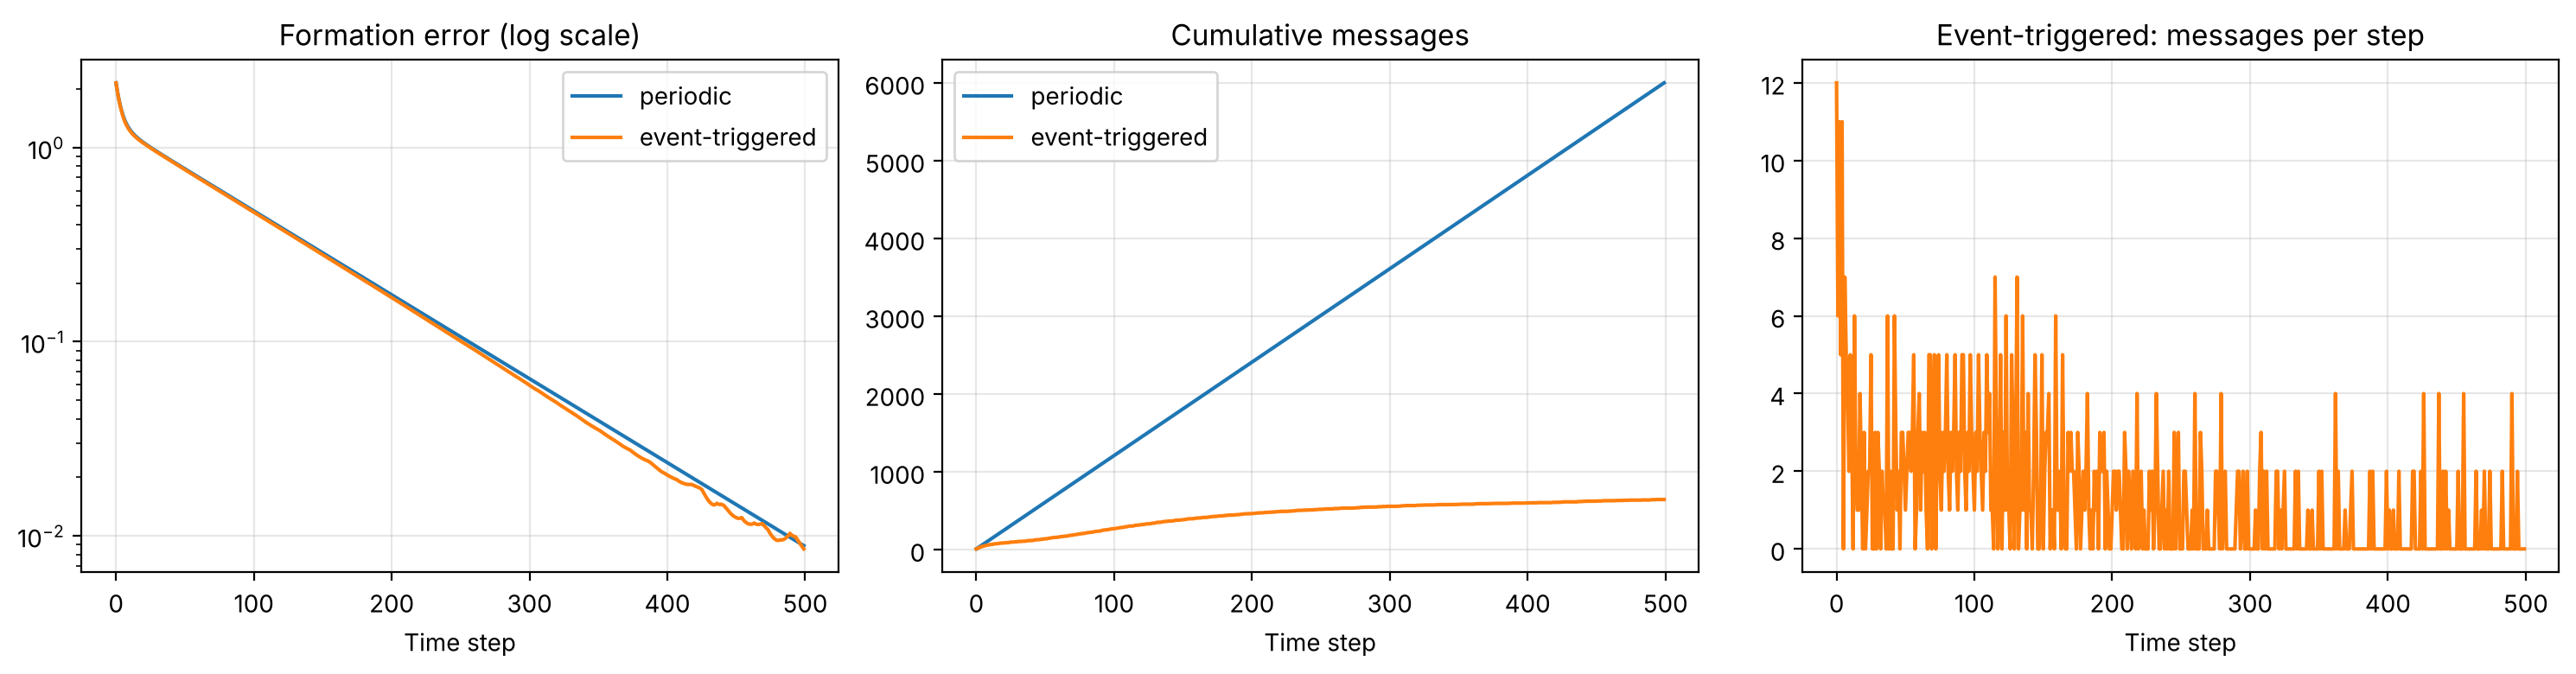

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].semilogy(periodic["errors"], label="periodic")
axes[0].semilogy(event["errors"], label="event-triggered")
axes[0].set_title("Formation error (log scale)")
axes[0].set_xlabel("Time step")

axes[1].plot(np.cumsum(periodic["messages"]), label="periodic")
axes[1].plot(np.cumsum(event["messages"]), label="event-triggered")
axes[1].set_title("Cumulative messages")
axes[1].set_xlabel("Time step")

axes[2].plot(event["messages"], color="C1")
axes[2].set_title("Event-triggered: messages per step")
axes[2].set_xlabel("Time step")

for a in axes:
    a.grid(True, alpha=0.3)
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig("plots/periodic_vs_event.png", dpi=200, bbox_inches="tight")
plt.show()

## Formation gallery (event-triggered controller)

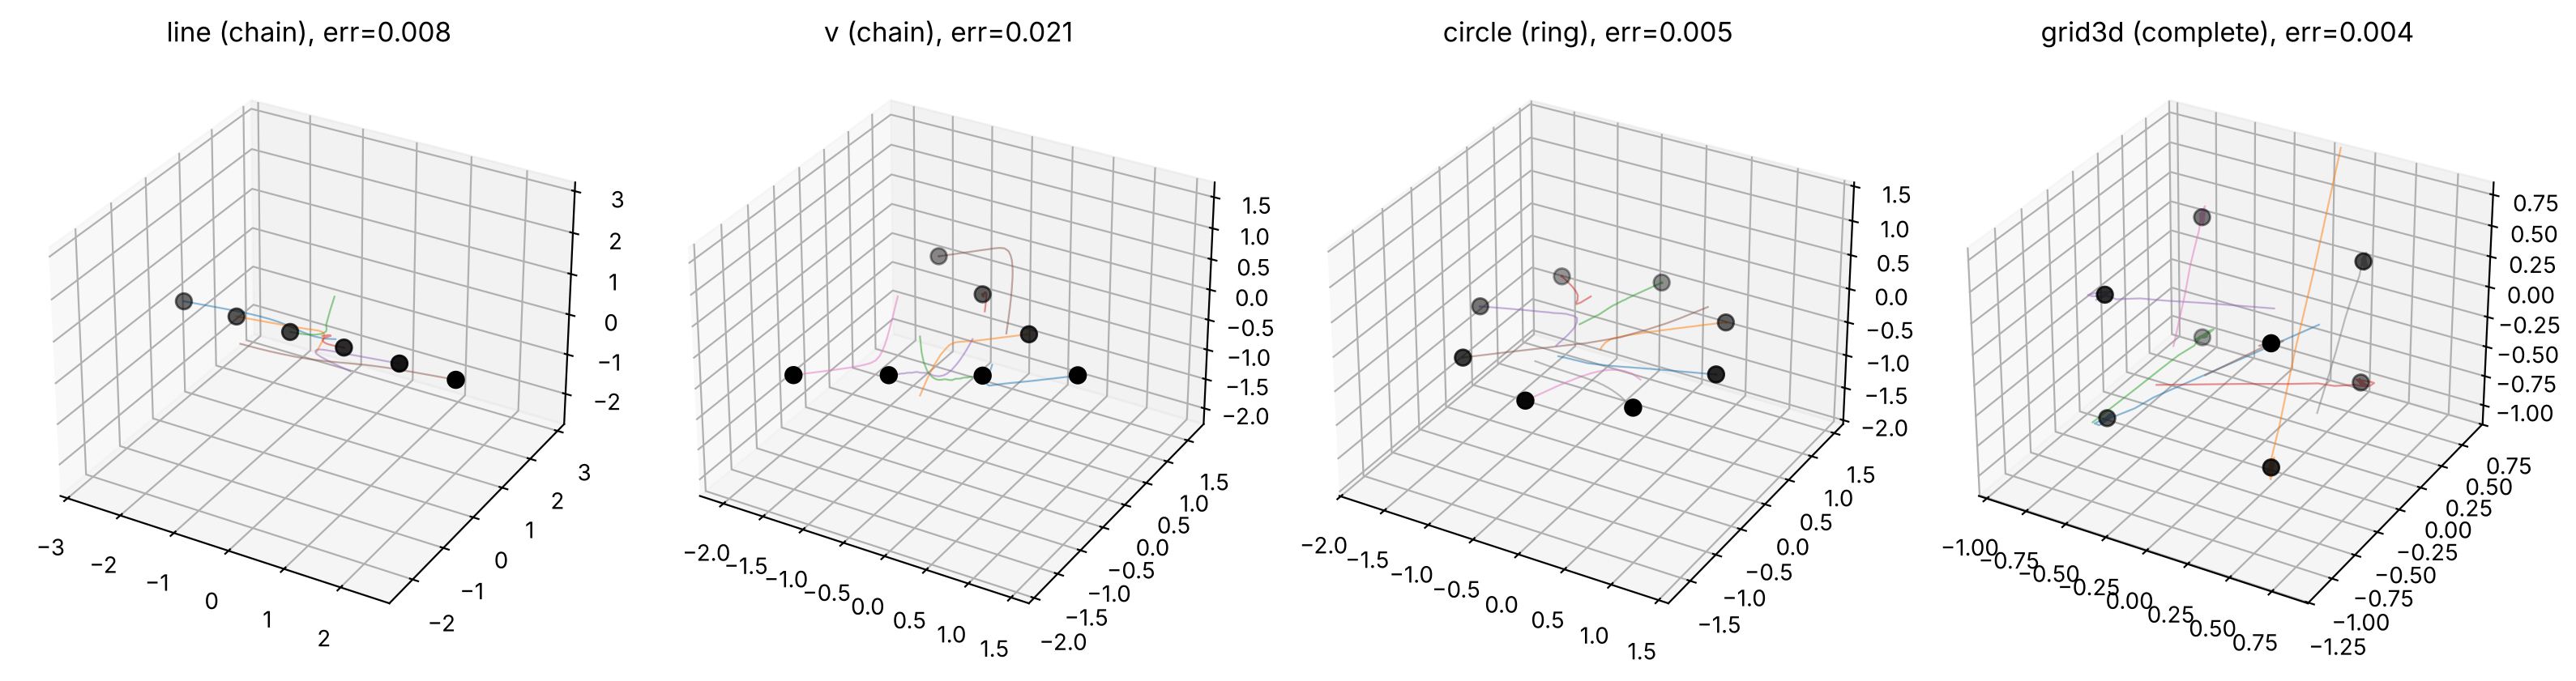

In [41]:
gallery = {
    "line":   dict(n=6, graph="chain"),
    "v":      dict(n=7, graph="chain"),
    "circle": dict(n=8, graph="ring"),
    "grid3d": dict(n=8, graph="complete"),
}

fig = plt.figure(figsize=(16, 4))
gallery_runs = {}
for k, (shape, cfg) in enumerate(gallery.items()):
    off = formations.make(shape, cfg["n"])
    ctrl = EventTriggeredFormationController(off, graph=cfg["graph"], gain=0.5, dt=DT)
    res = run(ctrl, off, steps=400, dt=DT, seed=k)
    gallery_runs[shape] = (off, cfg, res)

    p = res["trajectory"][-1]
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    for i in range(cfg["n"]):
        tr = res["trajectory"][:, i]
        ax.plot(tr[:, 0], tr[:, 1], tr[:, 2], lw=0.8, alpha=0.5)
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=50, c="k")
    ctr, r = p.mean(axis=0), np.abs(p - p.mean(axis=0)).max() + 0.5  # equal axes so shapes aren't squashed
    ax.set_xlim(ctr[0] - r, ctr[0] + r); ax.set_ylim(ctr[1] - r, ctr[1] + r); ax.set_zlim(ctr[2] - r, ctr[2] + r)
    ax.set_title(f"{shape} ({cfg['graph']}), err={res['final_error']:.3f}")
plt.tight_layout()
plt.savefig("plots/formation_gallery.png", dpi=200, bbox_inches="tight")
plt.show()

## Monte Carlo comparison — 20 random starts per formation

In [42]:
SEEDS = range(20)
rows = []
for shape, cfg in gallery.items():
    off = formations.make(shape, cfg["n"])
    stats = {}
    for name, make_ctrl in [
        ("periodic", lambda: FormationController(off, graph=cfg["graph"], gain=0.5)),
        ("event",    lambda: EventTriggeredFormationController(off, graph=cfg["graph"], gain=0.5, dt=DT)),
    ]:
        res = [run(make_ctrl(), off, steps=600, dt=DT, seed=s) for s in SEEDS]
        stats[name] = (np.mean([r["final_error"] for r in res]),
                       np.max([r["final_error"] for r in res]),
                       np.mean([r["total_messages"] for r in res]))
    rows.append((shape, cfg, stats))

print(f"{'shape':8}{'graph':10}{'periodic err':>14}{'event err (max)':>18}{'periodic msgs':>15}{'event msgs':>12}{'saved':>8}")
for shape, cfg, s in rows:
    saved = 100 * (1 - s["event"][2] / s["periodic"][2])
    print(f"{shape:8}{cfg['graph']:10}{s['periodic'][0]:>14.5f}{s['event'][0]:>11.4f} ({s['event'][1]:.3f}){s['periodic'][2]:>15.0f}{s['event'][2]:>12.0f}{saved:>7.1f}%")

shape   graph       periodic err   event err (max)  periodic msgs  event msgs   saved
line    chain            0.00070     0.0049 (0.010)           6000         642   89.3%
v       chain            0.00325     0.0059 (0.009)           7200         656   90.9%
circle  ring             0.00000     0.0050 (0.007)           9600         784   91.8%
grid3d  complete         0.00000     0.0049 (0.007)          33600        6507   80.6%


## Trade-off: how the trigger threshold trades accuracy for bandwidth

A bigger steady-state threshold `c0` means fewer messages but a larger residual formation error.

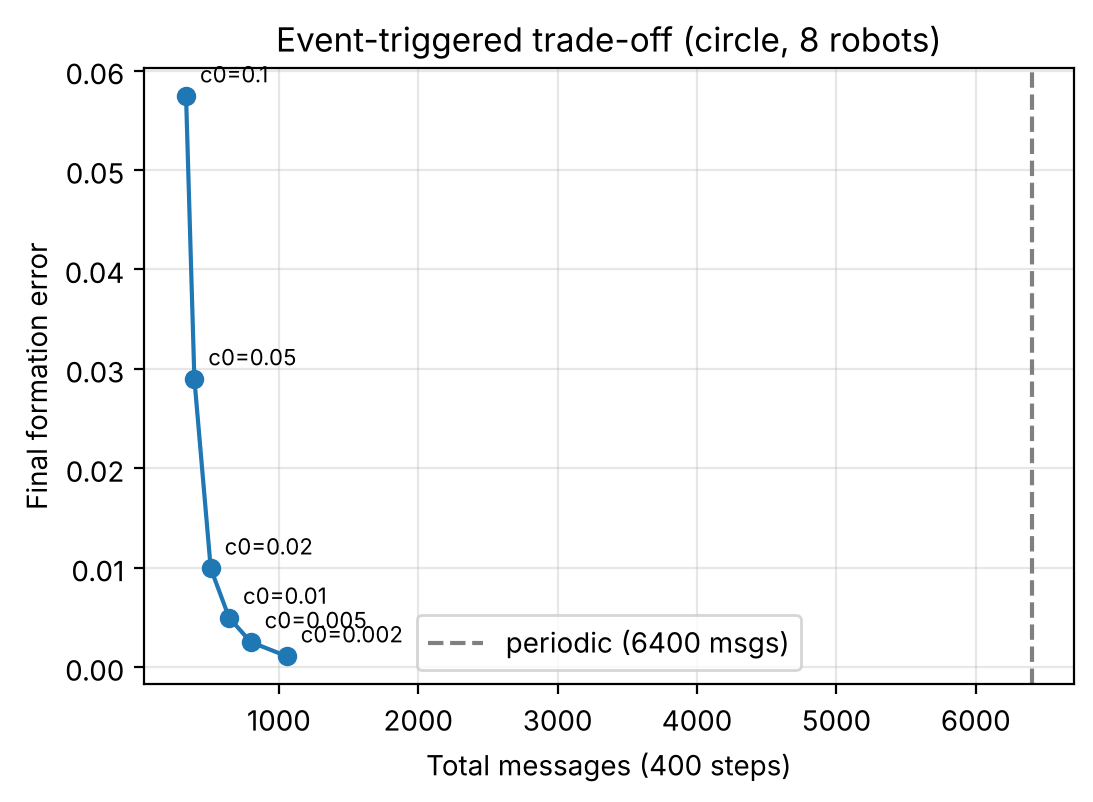

In [43]:
off = formations.make("circle", 8)
c0_values = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1]
tradeoff = []
for c0 in c0_values:
    res = [run(EventTriggeredFormationController(off, graph="ring", gain=0.5, dt=DT, c0=c0),
               off, steps=400, dt=DT, seed=s) for s in range(10)]
    tradeoff.append((np.mean([r["total_messages"] for r in res]), np.mean([r["final_error"] for r in res])))
periodic_msgs = run(FormationController(off, graph="ring", gain=0.5), off, 400, DT)["total_messages"]

msgs, errs = zip(*tradeoff)
plt.figure(figsize=(6, 4))
plt.plot(msgs, errs, "o-")
for c0, m, e in zip(c0_values, msgs, errs):
    plt.annotate(f"c0={c0}", (m, e), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.axvline(periodic_msgs, ls="--", color="gray", label=f"periodic ({periodic_msgs} msgs)")
plt.xlabel("Total messages (400 steps)")
plt.ylabel("Final formation error")
plt.title("Event-triggered trade-off (circle, 8 robots)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("plots/threshold_tradeoff.png", dpi=200, bbox_inches="tight")
plt.show()

## Animation — 8 robots forming a circle with event-triggered communication

Robots flash red on the steps they broadcast.

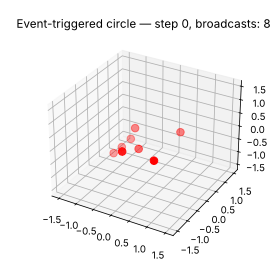

In [44]:
off, cfg, res = gallery_runs["circle"]
ctrl = EventTriggeredFormationController(off, graph="ring", gain=0.5, dt=DT)
np.random.seed(2)
env2 = PointMass3DEnv(num_agents=len(off), dt=DT)
traj, fired = [], []
for _ in range(200):
    before = None if ctrl.p_hat is None else ctrl.p_hat.copy()
    traj.append(env2.positions.copy())
    env2.step(ctrl.compute_velocities(env2.positions))
    fired.append(np.ones(len(off), bool) if before is None else np.any(ctrl.p_hat != before, axis=1))
traj = np.array(traj)

fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111, projection="3d")
lim = np.abs(traj).max() + 0.2
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
sc = ax.scatter([], [], [], s=60)

def update_et(f):
    p = traj[f]
    sc._offsets3d = (p[:, 0], p[:, 1], p[:, 2])
    sc.set_color(["red" if x else "tab:blue" for x in fired[f]])
    ax.set_title(f"Event-triggered circle — step {f}, broadcasts: {int(fired[f].sum())}")
    return sc,

ani_et = animation.FuncAnimation(fig, update_et, frames=range(0, len(traj), 2), interval=120)
ani_et.save("plots/event_triggered_circle.gif", writer=PillowWriter(fps=8), dpi=70)
plt.close(fig)
display(Image(filename="plots/event_triggered_circle.gif"))

## Tests

`tests/test_swarm.py` checks, over many random seeds:

- the environment integrates `p + v·dt` correctly,
- the original baseline controller always forms the line (the missing testing from the last commit),
- the generalised controller gives **identical** velocities to the baseline for a line,
- every formation shape converges for swarm sizes 3–12,
- the swarm centroid never drifts (symmetric graphs),
- the event-triggered controller converges *and* uses far fewer messages,
- shape generators are correct (circle neighbour spacing, unique grid points, etc.).

In [45]:
%%writefile tests/test_swarm.py
import os
import sys

import numpy as np
import pytest

sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

from env.point_mass_3d import PointMass3DEnv
from controllers.baseline import BaselineFormationController
from controllers import formations
from controllers.graphs import edges
from controllers.consensus import FormationController
from controllers.event_triggered import EventTriggeredFormationController
from experiments.metrics import offset_error
from experiments.runner import run

DT = 0.1


def line_spacing_error(p, s):
    return np.mean([abs(np.linalg.norm(p[i + 1] - p[i]) - s) for i in range(len(p) - 1)])


# ---------- environment ----------

def test_env_step_integrates_velocity():
    np.random.seed(0)
    env = PointMass3DEnv(num_agents=4, dt=0.1)
    p0 = env.positions.copy()
    v = np.random.randn(4, 3)
    env.step(v)
    assert np.allclose(env.positions, p0 + 0.1 * v)


def test_env_initial_positions_in_unit_cube():
    np.random.seed(1)
    env = PointMass3DEnv(num_agents=50)
    assert env.positions.shape == (50, 3)
    assert np.all(np.abs(env.positions) <= 1.0)


# ---------- original baseline line controller ----------

@pytest.mark.parametrize("seed", range(30))
@pytest.mark.parametrize("n", [2, 5, 8])
def test_baseline_forms_line(seed, n):
    np.random.seed(seed)
    env = PointMass3DEnv(num_agents=n, dt=DT)
    ctrl = BaselineFormationController(desired_spacing=1.0, gain=0.5)
    for _ in range(1500):
        env.step(ctrl.compute_velocities(env.positions))
    p = env.positions
    assert line_spacing_error(p, 1.0) < 1e-3
    # line lies along +x: y and z of all agents agree
    assert np.ptp(p[:, 1]) < 1e-3 and np.ptp(p[:, 2]) < 1e-3


@pytest.mark.parametrize("seed", range(10))
def test_generalised_controller_matches_baseline(seed):
    rng = np.random.default_rng(seed)
    n = 6
    p = rng.uniform(-2, 2, (n, 3))
    base = BaselineFormationController(desired_spacing=1.0, gain=0.5)
    gen = FormationController(formations.line(n, 1.0), graph="chain", gain=0.5)
    assert np.allclose(base.compute_velocities(p), gen.compute_velocities(p))


# ---------- generalised periodic controller ----------

SHAPE_GRAPHS = [("line", "chain"), ("v", "chain"), ("circle", "ring"), ("grid3d", "complete"), ("grid3d", "chain")]


@pytest.mark.parametrize("shape,graph", SHAPE_GRAPHS)
@pytest.mark.parametrize("n", [3, 5, 8, 12])
@pytest.mark.parametrize("seed", range(3))
def test_periodic_converges_all_shapes(shape, graph, n, seed):
    off = formations.make(shape, n)
    # keep k * dt * lambda_max(L) < 2 for the discrete-time loop to be stable
    gain = 0.5 if graph != "complete" else min(0.5, 1.0 / (n * DT))
    res = run(FormationController(off, graph=graph, gain=gain), off, steps=4000, dt=DT, seed=seed)
    assert res["final_error"] < 1e-3
    assert np.all(np.isfinite(res["trajectory"]))


@pytest.mark.parametrize("graph", ["chain", "ring", "complete"])
def test_centroid_is_preserved(graph):
    off = formations.make("v", 7)
    res = run(FormationController(off, graph=graph, gain=0.3), off, steps=300, dt=DT, seed=3)
    c = res["trajectory"].mean(axis=1)
    assert np.allclose(c, c[0], atol=1e-9)


def test_periodic_message_count():
    off = formations.line(5)
    ctrl = FormationController(off, graph="chain")
    ctrl.compute_velocities(np.zeros((5, 3)))
    assert ctrl.last_messages == 2 * (5 - 1)  # same as the notebook's baseline count


# ---------- event-triggered controller ----------

@pytest.mark.parametrize("shape,graph", SHAPE_GRAPHS[:4])
@pytest.mark.parametrize("seed", range(10))
def test_event_triggered_converges_and_saves_messages(shape, graph, seed):
    n = 8
    off = formations.make(shape, n)
    gain = 0.5 if graph != "complete" else 1.0 / (n * DT)
    steps = 1500
    et = run(EventTriggeredFormationController(off, graph=graph, gain=gain, dt=DT, c0=0.005),
             off, steps=steps, dt=DT, seed=seed)
    per = run(FormationController(off, graph=graph, gain=gain), off, steps=steps, dt=DT, seed=seed)
    assert et["final_error"] < 0.05
    assert et["total_messages"] < 0.25 * per["total_messages"]


def test_event_triggered_first_step_broadcasts_everyone():
    off = formations.circle(6)
    ctrl = EventTriggeredFormationController(off, graph="ring", dt=DT)
    ctrl.compute_velocities(np.random.default_rng(0).uniform(-1, 1, (6, 3)))
    assert ctrl.last_messages == 2 * len(edges("ring", 6))


def test_event_triggered_silent_at_rest():
    off = formations.circle(6)
    ctrl = EventTriggeredFormationController(off, graph="ring", dt=DT)
    p = off + np.array([1.0, 2.0, 3.0])  # already in formation
    for _ in range(50):
        v = ctrl.compute_velocities(p)
        assert np.allclose(v, 0)
    assert ctrl.last_messages == 0


def test_threshold_decays_to_c0():
    ctrl = EventTriggeredFormationController(formations.line(3), dt=DT, c0=0.01, c1=0.2, alpha=0.5)
    assert np.isclose(ctrl.threshold(), 0.21)
    ctrl.t = 100.0
    assert np.isclose(ctrl.threshold(), 0.01)


# ---------- formation shapes ----------

@pytest.mark.parametrize("shape", list(formations.SHAPES))
@pytest.mark.parametrize("n", [1, 2, 3, 7, 27])
def test_shapes_are_centred_and_sized(shape, n):
    off = formations.make(shape, n) if not (shape == "circle" and n < 3) else formations.make("line", n)
    assert off.shape == (n, 3)
    assert np.allclose(off.mean(axis=0), 0, atol=1e-9)


@pytest.mark.parametrize("n", [3, 6, 10])
def test_circle_neighbour_spacing(n):
    off = formations.circle(n, spacing=1.5)
    d = np.linalg.norm(np.roll(off, -1, axis=0) - off, axis=1)
    assert np.allclose(d, 1.5)


def test_grid_points_unique_and_on_lattice():
    off = formations.grid3d(20, spacing=2.0)
    assert len({tuple(np.round(p, 6)) for p in off}) == 20
    rel = (off - off.min(axis=0)) / 2.0
    assert np.allclose(rel, np.round(rel))


def test_offset_error_is_translation_invariant():
    off = formations.v_shape(5)
    assert offset_error(off + 7.0, off) < 1e-12
    assert offset_error(off * 2.0, off) > 0.1

Writing tests/test_swarm.py


In [46]:
!pip -q install pytest
!python -m pytest tests/ -q

...

...

....

...

...

....

... (159 outputs left out)

.

.

........... [ 92%]
..............

....                                                       [100%]
234 passed in 43.10s


## Results summary

- The generalised controller reproduces the baseline exactly and extends it to V, circle and 3D-grid formations with chain / ring / complete communication graphs.
- The event-triggered controller reaches almost the same formation (small residual error set by `c0`) while sending a small fraction of the messages — and goes **silent** once the swarm settles, while the baseline keeps sending `2(N-1)` messages every step forever.
- The threshold sweep gives a tunable accuracy-vs-bandwidth knob.
- All of it is covered by `tests/test_swarm.py`.

**Next ideas:** collision avoidance between robots, moving formations (leader following a path), noisy sensing / packet loss, and double-integrator (acceleration-controlled) dynamics.